# 实验1 线性方程组的求解
完成 LU、Jacobi、SOR、病态矩阵与右端扰动实验。所有范数统一为无穷范数。
下方输出来自同一源程序的实际运行；建议在本文件夹作为工作目录时执行。
停止标准为相对残差小于 `1e-6`。SOR 工程最优按网格内最少迭代次数定义，经典公式的特殊结构条件在报告中说明。


In [1]:
"""实验1：线性方程组的求解。所有误差和停止准则使用无穷范数。"""
from pathlib import Path
from functools import wraps
import json
import time
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

ROOT = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
OUT = ROOT / 'results'


def timer(func):
    """计时不包含打印和绘图；重复计时另取中位数。"""
    @wraps(func)
    def wrapper(*args, **kwargs):
        start = time.perf_counter()
        result = func(*args, **kwargs)
        wrapper.elapsed = time.perf_counter() - start
        print(f'[{func.__name__}] 耗时: {wrapper.elapsed:.6f} 秒')
        return result
    return wrapper


@timer
def solve_direct_numpy(A, b):
    return np.linalg.solve(A, b)


@timer
def solve_direct_custom(A, b):
    """带部分选主元的 LU 分解，合并存储 L 和 U，不改变输入。"""
    lu = A.astype(float).copy()
    rhs = b.astype(float).copy()
    n = len(b)
    for k in range(n - 1):
        p = k + np.argmax(np.abs(lu[k:, k]))
        if lu[p, k] == 0:
            raise np.linalg.LinAlgError('Singular matrix')
        # 同时交换已存的 L、剩余 U 和右端项，保持 PA=LU。
        if p != k:
            lu[[k, p], :] = lu[[p, k], :]
            rhs[[k, p]] = rhs[[p, k]]
        lu[k + 1:, k] /= lu[k, k]
        lu[k + 1:, k + 1:] -= np.outer(lu[k + 1:, k], lu[k, k + 1:])
    if lu[-1, -1] == 0:
        raise np.linalg.LinAlgError('Singular matrix')
    y = rhs.copy()
    for i in range(n):
        y[i] -= lu[i, :i] @ y[:i]
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        x[i] = (y[i] - lu[i, i + 1:] @ x[i + 1:]) / lu[i, i]
    return x


@timer
def solve_jacobi(A, b, tol=1e-6, max_iter=5000):
    """A=D+R，整块更新 x；每次更新后记录相对无穷范数残差。"""
    d = np.diag(A)
    R = A - np.diag(d)
    x = np.zeros(len(b))
    residuals = []
    norm_b = np.linalg.norm(b, np.inf)
    if norm_b == 0:
        return x, residuals
    for _ in range(max_iter):
        x = (b - R @ x) / d
        residuals.append(float(np.linalg.norm(b - A @ x, np.inf) / norm_b))
        if residuals[-1] < tol:
            break
    return x, residuals


@timer
def solve_sor(A, b, omega, tol=1e-6, max_iter=5000):
    """逐行原位更新；行前部用本轮新值，行后部用上一轮旧值。"""
    x = np.zeros(len(b))
    d = np.diag(A)
    residuals = []
    norm_b = np.linalg.norm(b, np.inf)
    if norm_b == 0:
        return x, residuals
    # 预取每行的非零非对角元，减少600维稀疏矩阵的零乘法。
    indices = [np.flatnonzero(A[i, :i]) for i in range(len(b))]
    upper = [np.flatnonzero(A[i, i + 1:]) + i + 1 for i in range(len(b))]
    lower_values = [A[i, j] for i, j in enumerate(indices)]
    upper_values = [A[i, j] for i, j in enumerate(upper)]
    for _ in range(max_iter):
        old = x.copy()
        for i in range(len(b)):
            sigma = lower_values[i] @ x[indices[i]] + upper_values[i] @ old[upper[i]]
            x[i] = (1 - omega) * old[i] + omega * (b[i] - sigma) / d[i]
        residuals.append(float(np.linalg.norm(b - A @ x, np.inf) / norm_b))
        if residuals[-1] < tol:
            break
    return x, residuals


def jacobi_radius(A):
    """本实验 A 对称、D>0，用与 J 相似的对称矩阵求特征值。"""
    s = np.sqrt(np.diag(A))
    similar = np.eye(len(A)) - A / s[:, None] / s[None, :]
    return float(np.max(np.abs(np.linalg.eigvalsh(similar))))


def sor_radius(A, omega):
    """T=(D+ωL)^(-1)[(1-ω)D-ωU]，前代构造实际迭代矩阵。"""
    d = np.diag(A)
    rhs = (1 - omega) * np.diag(d) - omega * np.triu(A, 1)
    T = np.zeros_like(A)
    for i in range(len(A)):
        T[i] = (rhs[i] - omega * (A[i, :i] @ T[:i])) / d[i]
    return float(np.max(np.abs(np.linalg.eigvals(T))))


def refine_sor_omega(A, left, right):
    """在网格最优附近用黄金分割细化实际谱半径的数值最小点。"""
    ratio = (np.sqrt(5) - 1) / 2
    c, d = right - ratio * (right - left), left + ratio * (right - left)
    fc, fd = sor_radius(A, c), sor_radius(A, d)
    for _ in range(24):
        if fc < fd:
            right, d, fd = d, c, fc
            c = right - ratio * (right - left)
            fc = sor_radius(A, c)
        else:
            left, c, fc = c, d, fd
            d = left + ratio * (right - left)
            fd = sor_radius(A, d)
    return float((left + right) / 2)


def solution_metrics(A, b, x, true):
    return {
        'absolute_residual': float(np.linalg.norm(b - A @ x, np.inf)),
        'relative_residual': float(np.linalg.norm(b - A @ x, np.inf) / np.linalg.norm(b, np.inf)),
        'absolute_error': float(np.linalg.norm(x - true, np.inf)),
        'relative_error': float(np.linalg.norm(x - true, np.inf) / np.linalg.norm(true, np.inf)),
    }


def plot_residuals(filename, title, curves):
    fig, ax = plt.subplots(figsize=(8, 4.4))
    for label, values in curves:
        ax.semilogy(np.arange(1, len(values) + 1), values, label=label)
    ax.axhline(1e-6, color='black', linestyle='--', linewidth=1, label='tolerance = 1e-6')
    ax.set(xlabel='Iteration', ylabel='Relative residual (infinity norm)', title=title)
    ax.grid(True, which='both', alpha=0.25)
    ax.legend(fontsize=9)
    fig.tight_layout()
    fig.savefig(OUT / filename, dpi=180)
    plt.close(fig)


def main():
    OUT.mkdir(exist_ok=True)
    tol = 1e-6
    with np.load(ROOT / 'cloth_data.npz') as data:
        A, b, true = data['A'], data['b'], data['x_true']
    print(f'成功加载矩阵 A 维度: {A.shape}')
    cond = float(np.linalg.cond(A, np.inf))
    rho = jacobi_radius(A)
    estimate = int(np.ceil(np.log(tol) / np.log(rho)))
    print(f'正常矩阵 κ∞={cond:.8f}, ρ(J)={rho:.10f}')

    print('\n--- 直接法性能对比 ---')
    # 先预热，再交替计时5次，避免一次调用的噪声决定结论。
    np.linalg.solve(A, b)
    times = {'numpy': [], 'custom_lu': []}
    for _ in range(5):
        for name, func in [('numpy', solve_direct_numpy), ('custom_lu', solve_direct_custom)]:
            start = time.perf_counter()
            x = func.__wrapped__(A, b)
            times[name].append(time.perf_counter() - start)
    x_np = solve_direct_numpy(A, b)
    x_lu = solve_direct_custom(A, b)
    direct = {'numpy': solution_metrics(A, b, x_np, true),
              'custom_lu': solution_metrics(A, b, x_lu, true),
              'solution_difference': float(np.linalg.norm(x_np - x_lu, np.inf))}
    for name in times:
        direct[name]['median_seconds'] = float(np.median(times[name]))
        direct[name]['timing_samples'] = times[name]
        m = direct[name]
        print(f"{name}: 中位耗时={m['median_seconds']:.6f}s, ||r||∞={m['absolute_residual']:.6e}, "
              f"真实误差={m['absolute_error']:.6e}")
    print(f"LU与NumPy解的差异: {direct['solution_difference']:.6e}")

    print('\n--- Jacobi 迭代 ---')
    print(f'预估约{estimate}步使通用误差缩小1e-6；实际按相对残差停止。')
    x_j, res_j = solve_jacobi(A, b, tol)
    jacobi = solution_metrics(A, b, x_j, true)
    jacobi.update(iterations=len(res_j), residuals=res_j, estimated_iterations=estimate, rho=rho)
    print(f"Jacobi: {len(res_j)}步, 相对残差={res_j[-1]:.6e}, 真实相对误差={jacobi['relative_error']:.6e}")
    plot_residuals('jacobi_normal.png', 'Jacobi - normal data', [('Jacobi', res_j)])

    print('\n--- SOR 参数比较 ---')
    formula_omega = float(2 / (1 + np.sqrt(1 - rho ** 2)))
    print(f'经典公式预测ω={formula_omega:.10f}，此矩阵不满足公式严格最优的特殊结构条件。')
    sor = []
    curves = []
    for omega in [1.0, 1.2, 1.5, 1.8, formula_omega]:
        x_s, residuals = solve_sor(A, b, omega, tol)
        row = solution_metrics(A, b, x_s, true)
        row.update(omega=omega, iterations=len(residuals), residuals=residuals,
                   seconds=solve_sor.elapsed, spectral_radius=sor_radius(A, omega))
        sor.append(row)
        curves.append((f'omega={omega:.4f}', residuals))
        print(f'ω={omega:.10f}: {len(residuals)}步, 相对残差={residuals[-1]:.6e}')
    # 工程最优定义：候选网格中达到相同残差标准所需步数最少。
    scan = []
    for omega in np.round(np.arange(1.00, 2.00, 0.01), 2):
        _, residuals = solve_sor.__wrapped__(A, b, float(omega), tol)
        scan.append({'omega': float(omega), 'iterations': len(residuals),
                     'residual': residuals[-1], 'spectral_radius': sor_radius(A, float(omega))})
    best_steps = min(row['iterations'] for row in scan)
    best_omegas = [row['omega'] for row in scan if row['iterations'] == best_steps]
    print(f'工程最优网格ω={best_omegas}, 均为{best_steps}步；并列时选最小ω={best_omegas[0]:.2f}。')
    grid_spectral_best = min(scan, key=lambda r: r['spectral_radius'])['omega']
    spectral_omega = refine_sor_omega(A, grid_spectral_best - 0.01, grid_spectral_best + 0.01)
    x_opt, res_opt = solve_sor(A, b, spectral_omega, tol)
    spectral_optimum = solution_metrics(A, b, x_opt, true)
    spectral_optimum.update(omega=spectral_omega, spectral_radius=sor_radius(A, spectral_omega),
                            iterations=len(res_opt), residuals=res_opt)
    print(f"实际谱半径数值最优ω≈{spectral_omega:.8f}, ρ(T)≈{spectral_optimum['spectral_radius']:.8f}, {len(res_opt)}步。")
    curves.append((f'spectral optimum={spectral_omega:.4f}', res_opt))
    plot_residuals('sor_comparison.png', 'SOR - relaxation parameter comparison', curves)
    fig, ax = plt.subplots(figsize=(8, 4.4))
    ax.plot([r['omega'] for r in scan], [r['iterations'] for r in scan])
    ax.axvline(formula_omega, color='tab:red', linestyle='--', label='classical formula')
    ax.set(xlabel='omega', ylabel='Iterations to tolerance', title='SOR - finite-step parameter search')
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUT / 'sor_scan.png', dpi=180)
    plt.close(fig)

    print('\n--- 病态矩阵与微小扰动 ---')
    with np.load(ROOT / 'cloth_ill_data.npz') as data:
        Ai, bi, bp, ti = data['A'], data['b'], data['b_perturbed'], data['x_true']
    cond_i = float(np.linalg.cond(Ai, np.inf))
    rho_i = jacobi_radius(Ai)
    xi, residuals_i = solve_jacobi(Ai, bi, tol, max_iter=200)
    clean = np.linalg.solve(Ai, bi)
    perturbed = np.linalg.solve(Ai, bp)
    db = float(np.linalg.norm(bp - bi, np.inf))
    dx = float(np.linalg.norm(perturbed - clean, np.inf))
    rel_b = db / float(np.linalg.norm(bi, np.inf))
    rel_x = dx / float(np.linalg.norm(clean, np.inf))
    ill = {'cond_inf': cond_i, 'rho': rho_i,
           'jacobi': solution_metrics(Ai, bi, xi, ti),
           'clean': solution_metrics(Ai, bi, clean, ti),
           'perturbed': solution_metrics(Ai, bp, perturbed, ti),
           'delta_b_absolute': db, 'delta_b_relative': rel_b,
           'delta_x_absolute': dx, 'delta_x_relative': rel_x,
           'amplification': rel_x / rel_b, 'condition_bound': cond_i * rel_b}
    ill['jacobi'].update(iterations=200, residuals=residuals_i,
                         minimum_iteration=int(np.argmin(residuals_i)) + 1,
                         minimum_residual=min(residuals_i))
    print(f'病态矩阵 κ∞={cond_i:.8f}, ρ(J)={rho_i:.10f}>1')
    print(f'病态Jacobi: 200步未收敛, 最后相对残差={residuals_i[-1]:.6e}')
    print(f"残差第{ill['jacobi']['minimum_iteration']}步最小={min(residuals_i):.6e}，随后增长。")
    print(f'输入绝对扰动={db:.6e}, 相对扰动={rel_b:.6e}')
    print(f'输出绝对变化={dx:.6e}, 相对变化={rel_x:.6e}')
    print(f'放大倍数={rel_x / rel_b:.6f}, 条件数给出的相对变化上界={cond_i * rel_b:.6e}')
    print(f"扰动前真实相对误差={ill['clean']['relative_error']:.6e}, 扰动后={ill['perturbed']['relative_error']:.6e}")
    plot_residuals('jacobi_ill.png', 'Jacobi - ill-conditioned data (200 iterations)', [('Jacobi ill', residuals_i)])

    results = {'norm': 'infinity', 'tol': tol, 'initial_guess': 'zeros',
               'shape': list(A.shape), 'nonzeros': int(np.count_nonzero(A)),
               'cond_inf': cond, 'direct': direct, 'jacobi': jacobi, 'sor': sor,
               'formula_omega': formula_omega, 'engineering_scan': scan,
               'spectral_optimum': spectral_optimum,
               'engineering_best_steps': best_steps, 'engineering_best_omegas': best_omegas,
               'ill': ill, 'numpy_version': np.__version__}
    (OUT / 'results.json').write_text(json.dumps(results, ensure_ascii=False, indent=2), encoding='utf-8')
    print('\n全部结果已保存到 results 文件夹。')


if __name__ == '__main__':
    main()


成功加载矩阵 A 维度: (600, 600)
正常矩阵 κ∞=784.21560036, ρ(J)=0.8952096509

--- 直接法性能对比 ---


[solve_direct_numpy] 耗时: 0.004629 秒


[solve_direct_custom] 耗时: 0.224327 秒
numpy: 中位耗时=0.005344s, ||r||∞=3.410605e-13, 真实误差=2.220446e-15
custom_lu: 中位耗时=0.231562s, ||r||∞=2.273737e-13, 真实误差=1.776357e-15
LU与NumPy解的差异: 2.664535e-15

--- Jacobi 迭代 ---
预估约125步使通用误差缩小1e-6；实际按相对残差停止。
[solve_jacobi] 耗时: 0.008738 秒
Jacobi: 51步, 相对残差=9.503421e-07, 真实相对误差=5.505557e-04



--- SOR 参数比较 ---
经典公式预测ω=1.3834652813，此矩阵不满足公式严格最优的特殊结构条件。
[solve_sor] 耗时: 0.121536 秒


ω=1.0000000000: 26步, 相对残差=8.900322e-07
[solve_sor] 耗时: 0.078302 秒


ω=1.2000000000: 17步, 相对残差=8.875646e-07
[solve_sor] 耗时: 0.084086 秒


... (2 outputs left out)

工程最优网格ω=[1.32, 1.33, 1.34, 1.35], 均为13步；并列时选最小ω=1.32。


[solve_sor] 耗时: 0.056755 秒
实际谱半径数值最优ω≈1.39644563, ρ(T)≈0.47602219, 15步。



--- 病态矩阵与微小扰动 ---
[solve_jacobi] 耗时: 0.030336 秒
病态矩阵 κ∞=44690.22357291, ρ(J)=1.0387073083>1
病态Jacobi: 200步未收敛, 最后相对残差=1.642518e-01
残差第17步最小=3.418158e-04，随后增长。
输入绝对扰动=8.621427e-08, 相对扰动=1.073952e-10
输出绝对变化=5.003606e-06, 相对变化=2.565980e-06
放大倍数=23892.865623, 条件数给出的相对变化上界=4.799517e-06
扰动前真实相对误差=2.619016e-15, 扰动后=2.565980e-06



全部结果已保存到 results 文件夹。


## 正常数据 Jacobi 残差
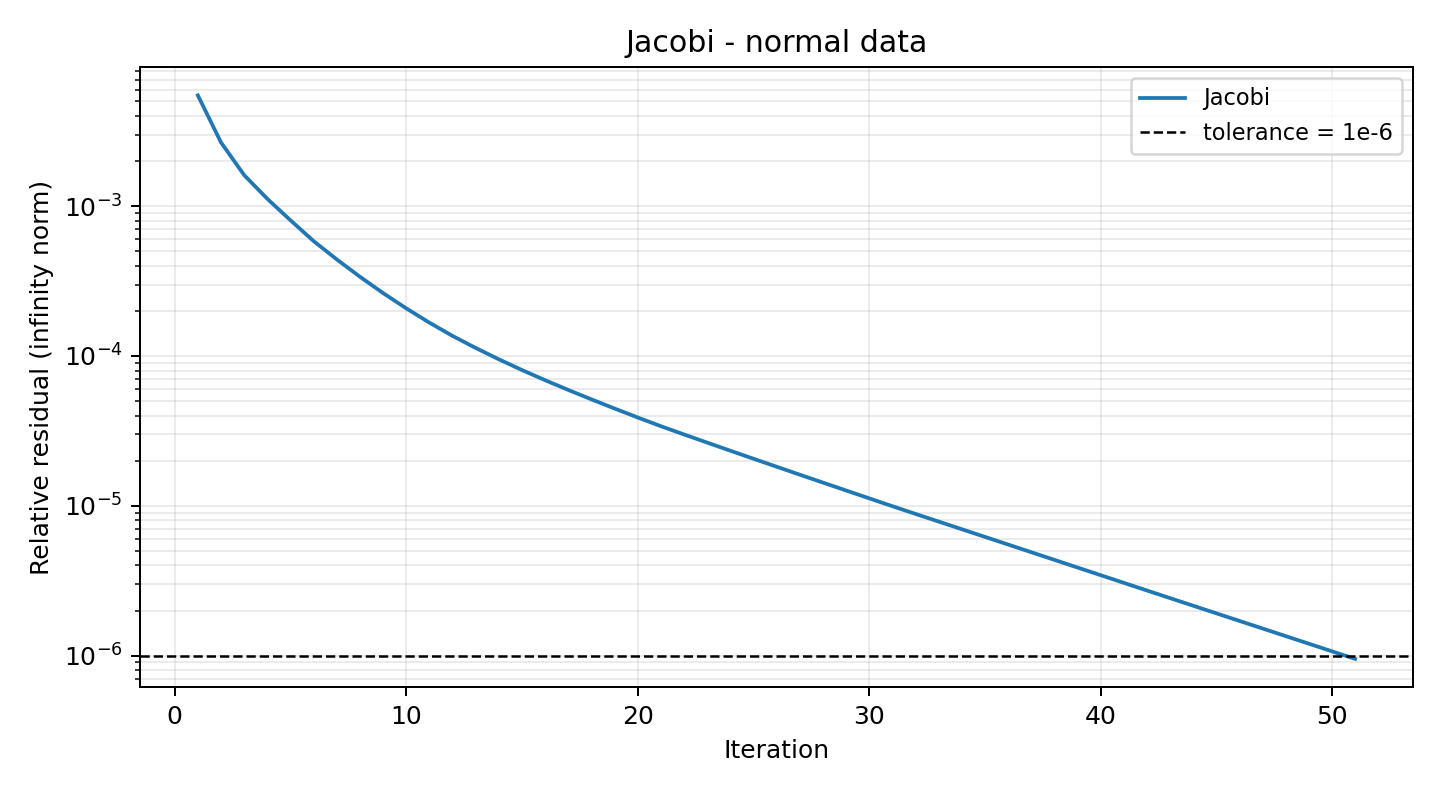


## SOR 参数与残差对比
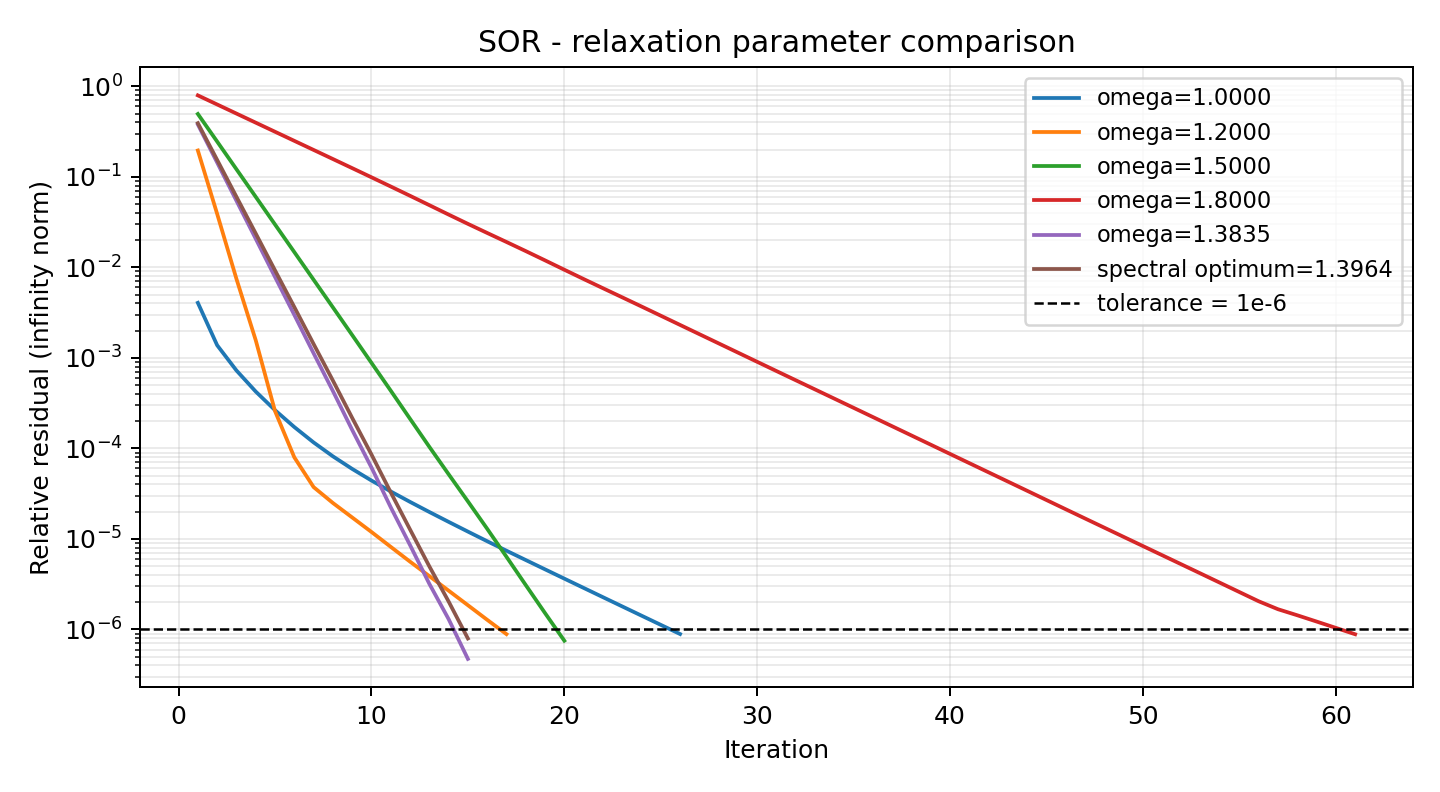


## SOR 有限步参数扫描
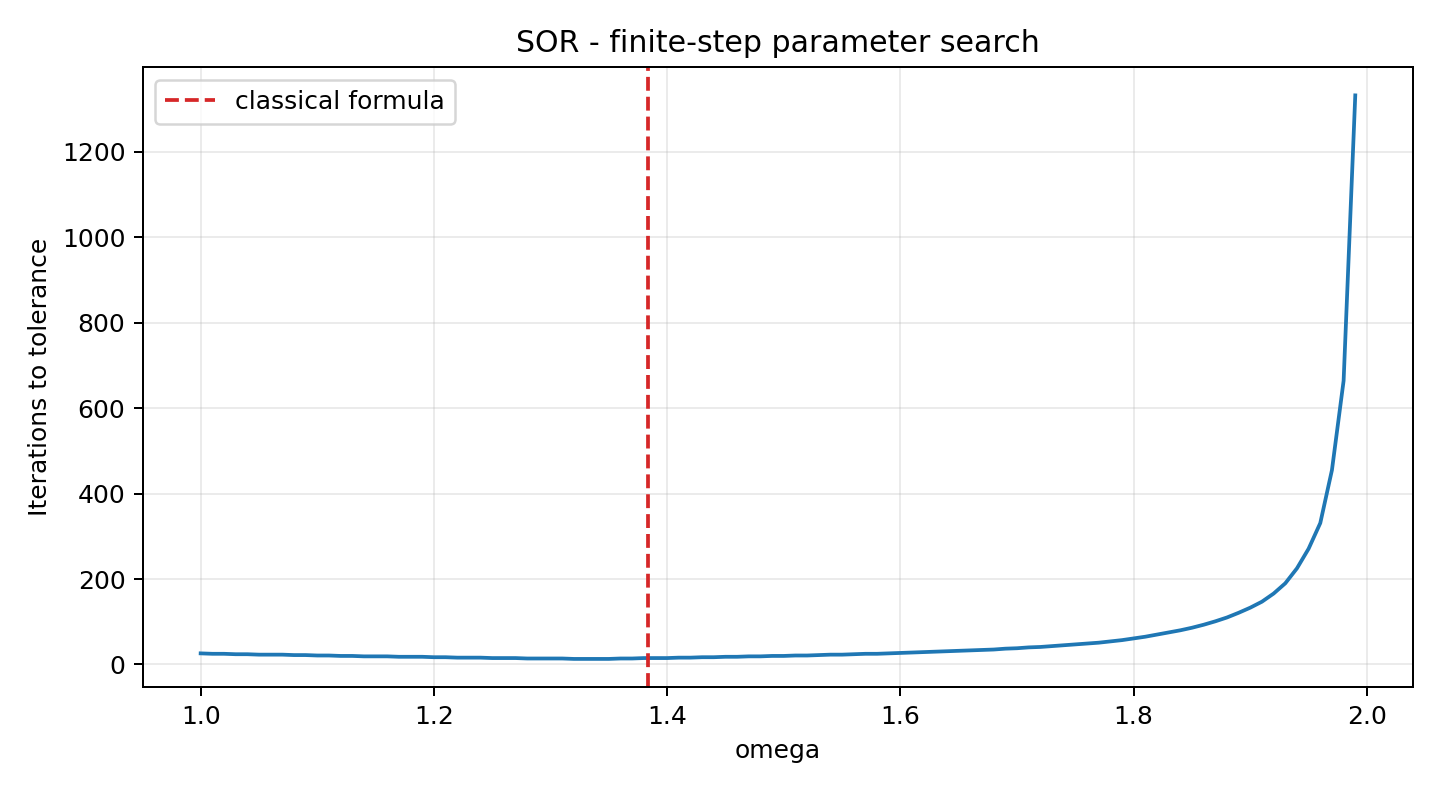


## 病态数据 Jacobi 残差
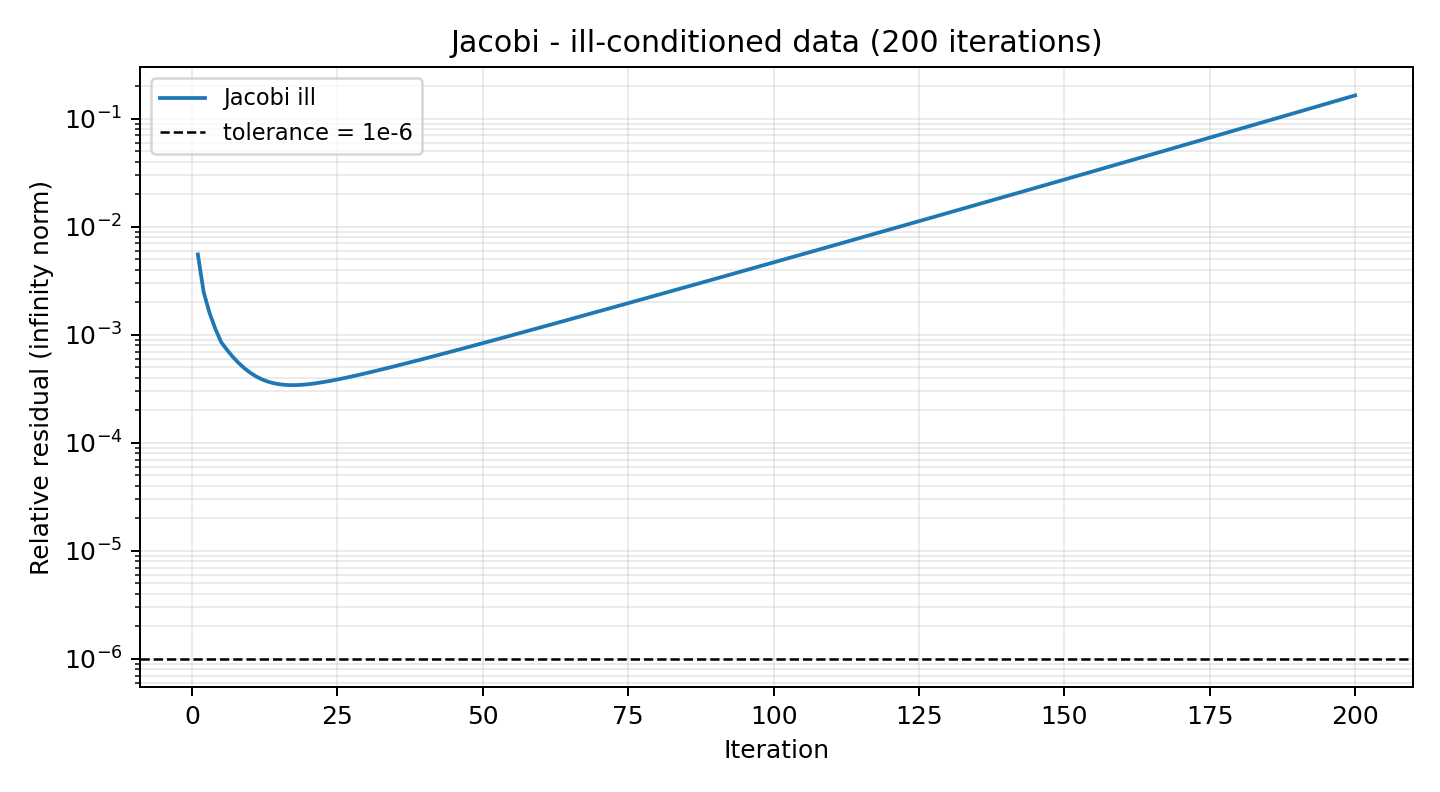
